# Day 15: NumPy Statistical Analysis

## Objective
Analyze a numerical dataset using NumPy statistical functions and identify important patterns in the data.

## Learning Goals
- Calculate mean, median, standard deviation, minimum, and maximum.
- Compare mean and median.
- Identify unusually high or low values.
- Summarize observations from a student performance dataset.
- Visualize numerical data using Matplotlib.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Libraries imported successfully!")

NumPy version: 2.5.4
Libraries imported successfully!


In [3]:
students = np.array([
    "S1", "S2", "S3", "S4", "S5",
    "S6", "S7", "S8", "S9", "S10",
    "S11", "S12", "S13", "S14", "S15"
])

marks = np.array([
    78, 85, 92, 67, 73,
    88, 90, 81, 76, 95,
    69, 84, 91, 72, 45
])

print("Student Performance Dataset")
print("-" * 35)

for student, mark in zip(students, marks):
    print(f"{student}: {mark}")

print("\nTotal students:", len(marks))
print("Marks array:", marks)

Student Performance Dataset
-----------------------------------
S1: 78
S2: 85
S3: 92
S4: 67
S5: 73
S6: 88
S7: 90
S8: 81
S9: 76
S10: 95
S11: 69
S12: 84
S13: 91
S14: 72
S15: 45

Total students: 15
Marks array: [78 85 92 67 73 88 90 81 76 95 69 84 91 72 45]


In [4]:
mean_marks = np.mean(marks)
median_marks = np.median(marks)
std_marks = np.std(marks)
minimum_marks = np.min(marks)
maximum_marks = np.max(marks)

print("STATISTICAL SUMMARY")
print("-" * 30)
print(f"Mean: {mean_marks:.2f}")
print(f"Median: {median_marks:.2f}")
print(f"Standard Deviation: {std_marks:.2f}")
print(f"Minimum Marks: {minimum_marks}")
print(f"Maximum Marks: {maximum_marks}")

STATISTICAL SUMMARY
------------------------------
Mean: 79.07
Median: 81.00
Standard Deviation: 12.47
Minimum Marks: 45
Maximum Marks: 95


In [5]:
print(f"Mean: {mean_marks:.2f}")
print(f"Median: {median_marks:.2f}")

difference = abs(mean_marks - median_marks)
print(f"Absolute Difference: {difference:.2f}")

if mean_marks > median_marks:
    print("Mean is greater than median.")
elif mean_marks < median_marks:
    print("Mean is less than median.")
else:
    print("Mean and median are equal.")

Mean: 79.07
Median: 81.00
Absolute Difference: 1.93
Mean is less than median.


In [6]:
q1 = np.percentile(marks, 25)
q3 = np.percentile(marks, 75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

potential_outliers = marks[
    (marks < lower_bound) | (marks > upper_bound)
]

print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")

print("\nPotential outlier marks:")
print(potential_outliers)

Q1: 72.50
Q3: 89.00
IQR: 16.50
Lower Bound: 47.75
Upper Bound: 113.75

Potential outlier marks:
[45]


In [7]:
highest_index = np.argmax(marks)
lowest_index = np.argmin(marks)

print(
    "Highest Scorer:",
    students[highest_index],
    "-",
    marks[highest_index]
)

print(
    "Lowest Scorer:",
    students[lowest_index],
    "-",
    marks[lowest_index]
)

Highest Scorer: S10 - 95
Lowest Scorer: S15 - 45


In [9]:
count_above_80 = np.sum(marks > 80)
count_below_60 = np.sum(marks < 60)
count_equal_or_above_75 = np.sum(marks >= 75)

print("OBSERVATIONS")
print("-" * 35)

print(
    f"1. Average student marks are {mean_marks:.2f}, "
    f"while the median is {median_marks:.2f}."
)

print(
    f"2. {count_above_80} students scored above 80."
)

print(
    f"3. {count_below_60} students scored below 60."
)

print(
    f"4. {count_equal_or_above_75} students scored 75 or above."
)

print(
    f"5. The difference between the highest and lowest marks "
    f"is {maximum_marks - minimum_marks}."
)

print("Potential outliers according to the IQR method:",
      potential_outliers)

OBSERVATIONS
-----------------------------------
1. Average student marks are 79.07, while the median is 81.00.
2. 8 students scored above 80.
3. 1 students scored below 60.
4. 10 students scored 75 or above.
5. The difference between the highest and lowest marks is 50.
Potential outliers according to the IQR method: [45]


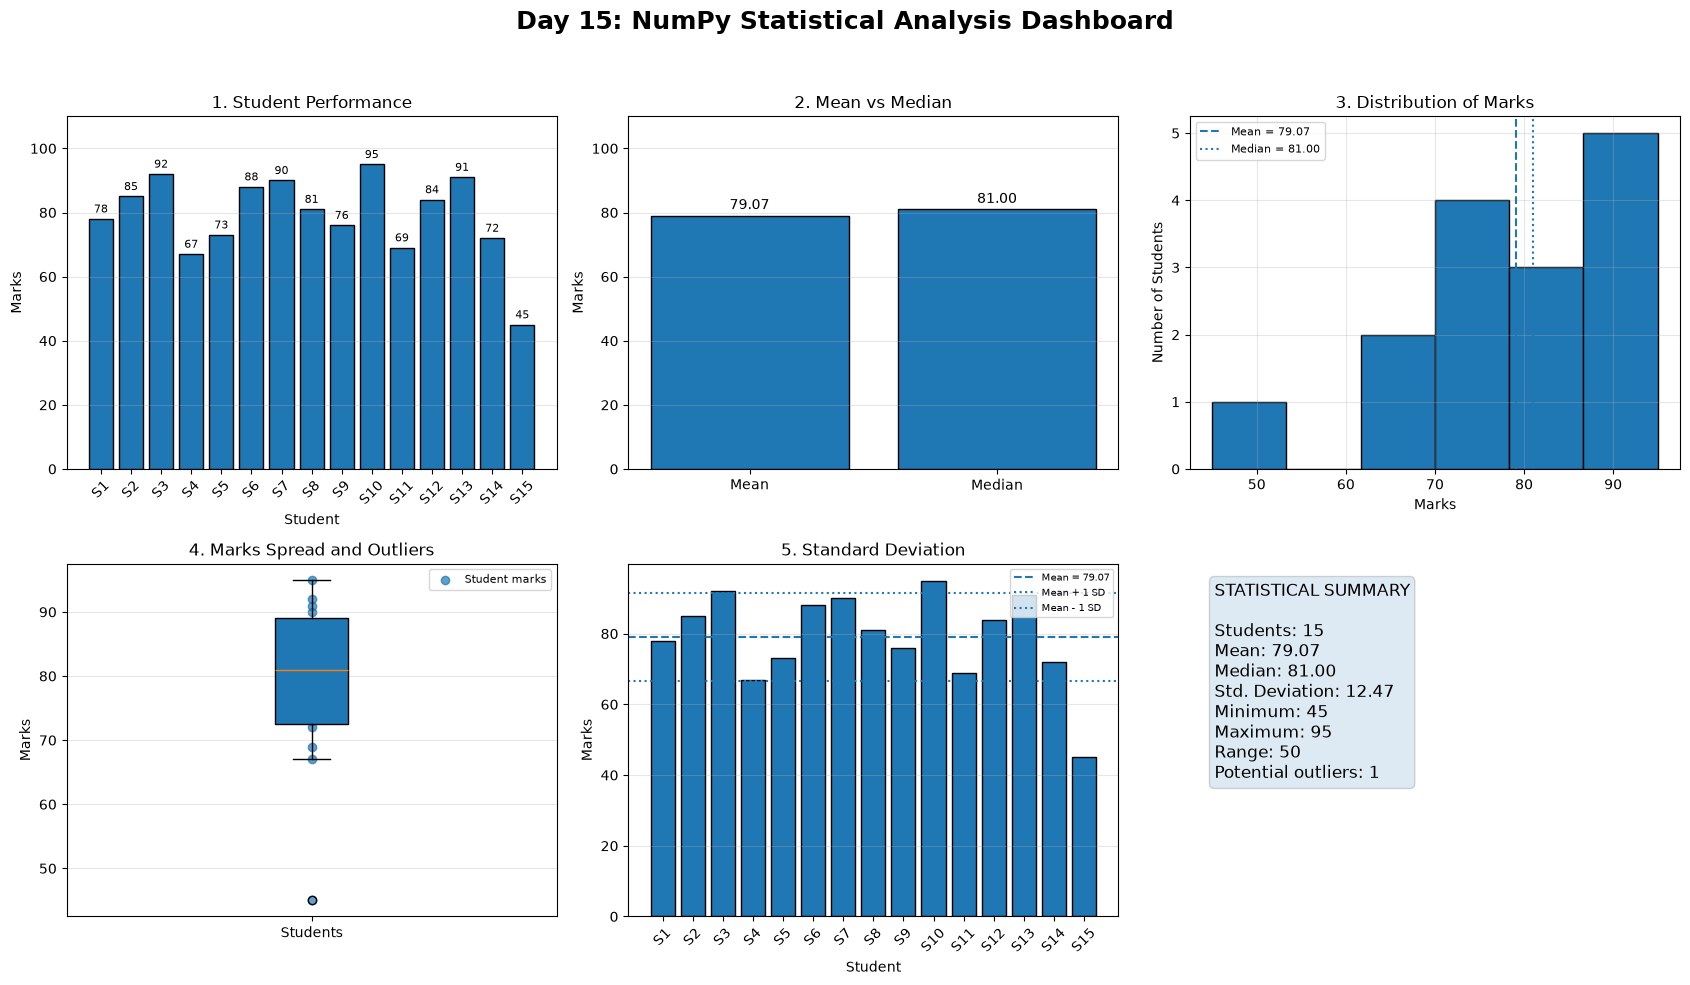

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

fig.suptitle(
    "Day 15: NumPy Statistical Analysis Dashboard",
    fontsize=18,
    fontweight="bold"
)

# 1. Student-wise marks
axes[0, 0].bar(students, marks, edgecolor="black")
axes[0, 0].set_title("1. Student Performance")
axes[0, 0].set_xlabel("Student")
axes[0, 0].set_ylabel("Marks")
axes[0, 0].set_ylim(0, 110)
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(axis="y", alpha=0.3)

for i, value in enumerate(marks):
    axes[0, 0].text(i, value + 2, str(value),
                    ha="center", fontsize=8)

# 2. Mean vs median
axes[0, 1].bar(
    ["Mean", "Median"],
    [mean_marks, median_marks],
    edgecolor="black"
)
axes[0, 1].set_title("2. Mean vs Median")
axes[0, 1].set_ylabel("Marks")
axes[0, 1].set_ylim(0, 110)
axes[0, 1].grid(axis="y", alpha=0.3)

for i, value in enumerate([mean_marks, median_marks]):
    axes[0, 1].text(i, value + 2, f"{value:.2f}",
                    ha="center")

# 3. Distribution histogram
axes[0, 2].hist(marks, bins=6, edgecolor="black")
axes[0, 2].axvline(
    mean_marks, linestyle="--",
    label=f"Mean = {mean_marks:.2f}"
)
axes[0, 2].axvline(
    median_marks, linestyle=":",
    label=f"Median = {median_marks:.2f}"
)
axes[0, 2].set_title("3. Distribution of Marks")
axes[0, 2].set_xlabel("Marks")
axes[0, 2].set_ylabel("Number of Students")
axes[0, 2].legend(fontsize=8)
axes[0, 2].grid(alpha=0.3)

# 4. Box plot and potential outliers
axes[1, 0].boxplot(marks, patch_artist=True)
axes[1, 0].scatter(
    np.ones(len(marks)), marks,
    alpha=0.7, label="Student marks"
)
axes[1, 0].set_title("4. Marks Spread and Outliers")
axes[1, 0].set_ylabel("Marks")
axes[1, 0].set_xticks([1])
axes[1, 0].set_xticklabels(["Students"])
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(axis="y", alpha=0.3)

# 5. Standard deviation from the mean
axes[1, 1].bar(students, marks, edgecolor="black")
axes[1, 1].axhline(
    mean_marks, linestyle="--",
    label=f"Mean = {mean_marks:.2f}"
)
axes[1, 1].axhline(
    mean_marks + std_marks, linestyle=":",
    label="Mean + 1 SD"
)
axes[1, 1].axhline(
    mean_marks - std_marks, linestyle=":",
    label="Mean - 1 SD"
)
axes[1, 1].set_title("5. Standard Deviation")
axes[1, 1].set_xlabel("Student")
axes[1, 1].set_ylabel("Marks")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].legend(fontsize=7)
axes[1, 1].grid(axis="y", alpha=0.3)

# 6. Statistical summary
axes[1, 2].axis("off")

summary_text = (
    "STATISTICAL SUMMARY\n\n"
    f"Students: {len(marks)}\n"
    f"Mean: {mean_marks:.2f}\n"
    f"Median: {median_marks:.2f}\n"
    f"Std. Deviation: {std_marks:.2f}\n"
    f"Minimum: {minimum_marks}\n"
    f"Maximum: {maximum_marks}\n"
    f"Range: {maximum_marks - minimum_marks}\n"
    f"Potential outliers: {len(potential_outliers)}"
)

axes[1, 2].text(
    0.05, 0.95, summary_text,
    va="top", fontsize=12,
    bbox=dict(boxstyle="round", alpha=0.15)
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [11]:
print("=" * 45)
print("DAY 15: FINAL STATISTICAL SUMMARY")
print("=" * 45)

print(f"Total Students: {len(marks)}")
print(f"Mean: {mean_marks:.2f}")
print(f"Median: {median_marks:.2f}")
print(f"Standard Deviation: {std_marks:.2f}")
print(f"Minimum: {minimum_marks}")
print(f"Maximum: {maximum_marks}")
print(f"Range: {maximum_marks - minimum_marks}")

print("\nPotential Outliers:", potential_outliers)
print("\nAnalysis completed successfully!")

DAY 15: FINAL STATISTICAL SUMMARY
Total Students: 15
Mean: 79.07
Median: 81.00
Standard Deviation: 12.47
Minimum: 45
Maximum: 95
Range: 50

Potential Outliers: [45]

Analysis completed successfully!
